## Albedo Analysis
Assess how changes in albedo configuration affect model output.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [2]:
from pathlib import Path
from dotenv import load_dotenv
load_dotenv(Path.cwd().parents[1] / ".env")

True

In [3]:
# Load the CSV data
df = pd.read_csv('../combined_results.csv')
df.head()

,site,latitude,longitude,output_years,bias_s00000000_ghec,rmse_s00000000_ghec,model_snow_days_s00000000_ghec,snotel_snow_days,mean_snotel_swe,var_snotel_swe,...,model_snow_days_s01011010_ghec,bias_s01011010_ghelaps,rmse_s01011010_ghelaps,model_snow_days_s01011010_ghelaps,bias_s01011010_ghelaps_veg,rmse_s01011010_ghelaps_veg,model_snow_days_s01011010_ghelaps_veg,bias_s01012010_ghelaps,rmse_s01012010_ghelaps,model_snow_days_s01012010_ghelaps
0,Forestdale Creek,38.68,-119.96,16.0,-95.3,168.5,2909,3065,277.6,150622.6,...,3678,55.8,106.6,3152,-33.4,86.0,2856.0,55.9,107.0,3155
1,Horse Meadow,38.84,-119.89,11.2,-22.0,66.2,1627,1704,127.6,38347.5,...,1984,19.7,64.6,1723,-23.3,63.5,1562.0,20.1,65.1,1728
2,Burnside Lake,38.72,-119.89,16.0,-7.2,89.5,3124,3055,196.3,83372.0,...,3760,78.0,150.9,3269,17.9,63.3,3037.0,78.0,150.8,3267
3,Summit Meadow,38.40,-119.54,9.2,-9.4,67.5,1186,1153,103.5,25719.7,...,1468,38.3,84.2,1312,-4.3,38.0,1177.0,38.4,84.6,1312
4,Carson Pass,38.69,-120.00,14.0,-67.7,124.9,2500,2705,233.7,107471.6,...,3138,28.2,84.4,2719,-35.7,72.2,2527.0,28.3,84.7,2722


In [4]:
# Remove sites where 'output_years' < 5
df = df[df['output_years'] >= 5]

In [5]:
# Drop upper san juan since it didn't get run in veg
df = df[df['site'] != 'Upper San Juan']

### Normalized Bias Calculation
Normalize bias by dividing by the mean SWE at each site.

In [6]:
# Create a dataframe for bias
bias_df = df[['site', 'latitude', 'longitude', 'mean_snotel_swe', 'var_snotel_swe',
              'bias_s00000000_ghec', 'bias_s01011010_ghec', 'bias_s01011010_ghelaps',
              'bias_s01011010_gbc', 'bias_s01011010_ghelaps_veg', 'bias_s01012010_ghelaps']].copy()

In [7]:
bias_df['nbias_s00000000_ghec'] = bias_df['bias_s00000000_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghec'] = bias_df['bias_s01011010_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghelaps'] = bias_df['bias_s01011010_ghelaps'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_gbc'] = bias_df['bias_s01011010_gbc'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghelaps_veg'] = bias_df['bias_s01011010_ghelaps_veg'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01012010_ghelaps'] = bias_df['bias_s01012010_ghelaps'] / bias_df['mean_snotel_swe']

In [ ]:
# Plot normalized bias
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc', 'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']
titles = ['nBias Baseline', 'nBias HE-Clean', 'nBias HE-LAPS', 'nBias BRDF', 'nBias Laps Veg', 'nBias Partition V2']

# Set color scale limits centered on 0
vmin = -1
vmax = 1

# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(3, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(bias_df['longitude'], bias_df['latitude'],
                         c=bias_df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(bias_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {bias_df[column].min():.2f} to {bias_df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 0)")

### Snow Days

In [ ]:
# Create a dataframe for snow days
snow_days_df = df[['site',
                   'latitude',
                   'longitude',
                   'output_years',
                   'mean_snotel_swe',
                   'var_snotel_swe',
                   'snotel_snow_days',
                   'model_snow_days_s00000000_ghec',
                   'model_snow_days_s01011010_ghec',
                   'model_snow_days_s01011010_ghelaps',
                   'model_snow_days_s01011010_gbc']].copy()

In [ ]:
# Calculate various differences normalized by number of years
snow_days_df['dsnow_days_s00000000_ghec'] = (snow_days_df['model_snow_days_s00000000_ghec'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_ghec'] = (snow_days_df['model_snow_days_s01011010_ghec'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_ghelaps'] = (snow_days_df['model_snow_days_s01011010_ghelaps'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_gbc'] = (snow_days_df['model_snow_days_s01011010_gbc'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']

snow_days_df['dsnow_days_hec_helaps'] = (snow_days_df['model_snow_days_s01011010_ghec'] - snow_days_df['model_snow_days_s01011010_ghelaps']) / snow_days_df['output_years']

In [ ]:
# Create figure with 2x2 grid of subplots for normalized bias
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['dsnow_days_s00000000_ghec', 'dsnow_days_s01011010_gbc', 'dsnow_days_s01011010_ghelaps', 'dsnow_days_hec_helaps']
titles = ['dSnow Days Baseline', 'dSnow Days (GBC)', 'dSnow Days (GHELAPS)', 'dSnow Days (HE - HELAPS)']

# Set color scale limits centered on 0
vmin, vmax = (-100, 100)


# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(snow_days_df['longitude'], snow_days_df['latitude'],
                         c=snow_days_df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(snow_days_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {snow_days_df[column].min():.2f} to {snow_days_df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 0)")

In [ ]:
# Histogram of dsnow_days_hec_helaps
plt.figure(figsize=(10, 6))
plt.hist(snow_days_df['dsnow_days_hec_helaps'], bins=30, color='skyblue', edgecolor='black')
plt.title('Histogram of dSnow Days (HEC - HELAPS)', fontsize=14, fontweight='bold')
plt.xlabel('dSnow Days per Year', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Plot mean and stddev lines
mean_diff = snow_days_df['dsnow_days_hec_helaps'].mean()
stddev_diff = snow_days_df['dsnow_days_hec_helaps'].std()
plt.axvline(mean_diff, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_diff:.2f}')
plt.axvline(mean_diff + stddev_diff, color='green', linestyle='dashed', linewidth=2, label=f'Std Dev: {stddev_diff:.2f}')
plt.axvline(mean_diff - stddev_diff, color='green', linestyle='dashed', linewidth=2)
plt.legend()


### Elevational Comparison

In [8]:
# Load topography data
import os
SNOTEL_PATH = Path(os.getenv('SNOTEL_PATH'))
snotel_topo = pd.read_csv(SNOTEL_PATH / 'snotel_land_data.csv')

In [9]:
# Merge bias_df with snotel_topo on site name
# Need to match 'site' in bias_df with 'SNOTEL Name' in snotel_topo
merged_df = bias_df.merge(snotel_topo[['SNOTEL Name', 'ELEVATION']], 
                          left_on='site', right_on='SNOTEL Name', how='inner')

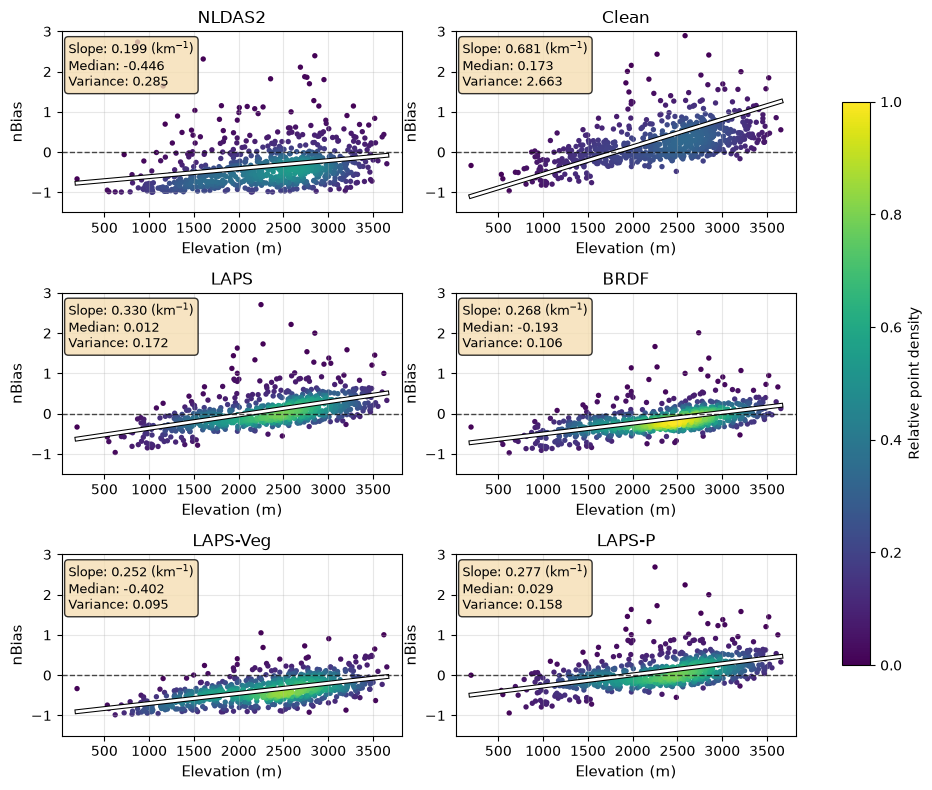

Number of sites plotted: 764

Points cut off by y-axis max (3):
NLDAS2: 1
Clean: 9
LAPS: 1
BRDF: 0
LAPS-Veg: 0
LAPS-P: 1


In [16]:
# Bias and Elevation
from scipy.stats import gaussian_kde
import matplotlib.patheffects as pe

# Create 3x2 subplot figure
fig, axes = plt.subplots(3, 2, figsize=(10, 8))

# Flatten axes for easier iteration
axes = axes.flatten()

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec','nbias_s01011010_ghec','nbias_s01011010_ghelaps', 'nbias_s01011010_gbc', 'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Define titles for each subplot
titles = ['NLDAS2','Clean','LAPS', 'BRDF', 'LAPS-Veg', 'LAPS-P']

# y-axis limits
ymin, ymax = -1.5, 3

# Outline so lines stay visible on top of the colored points
outline = [pe.Stroke(linewidth=3.5, foreground='black'), pe.Normal()]

# Track how many points get cut off by the y-axis max in each panel
n_cutoff = []

# Keep scatter collections and densities to apply a shared color scale afterwards
scatters = []
densities = []

# Create density-colored scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    ax = axes[idx]
    
    # Calculate best fit line
    # Remove any NaN values for fitting
    valid_mask = ~(merged_df['ELEVATION'].isna() | merged_df[bias_col].isna())
    x_data = merged_df.loc[valid_mask, 'ELEVATION']
    y_data = merged_df.loc[valid_mask, bias_col]
    
    # Estimate point density with a Gaussian KDE, draw densest points last
    xy = np.vstack([x_data, y_data])
    z = gaussian_kde(xy)(xy)
    order = z.argsort()
    sc = ax.scatter(x_data.to_numpy()[order], y_data.to_numpy()[order], c=z[order],
                    s=15, cmap='viridis', linewidths=0, rasterized=True)
    scatters.append(sc)
    densities.append(z[order])
    
    # Count values cut off by the y-axis max
    n_cutoff.append(int((y_data > ymax).sum()))
    
    # Fit a line: y = slope * x + intercept
    slope, intercept = np.polyfit(x_data, y_data, 1)
    
    # Create x values for the line
    x_line = np.array([x_data.min(), x_data.max()])
    y_line = slope * x_line + intercept
    
    # Plot the best fit line
    ax.plot(x_line, y_line, color='white', linewidth=2, path_effects=outline)
    
    # Add text box with slope (per km), median bias, and bias variance
    slope_km = slope * 1000
    textstr = (f'Slope: {slope_km:.3f} (km$^{{-1}}$)\n'
               f'Median: {y_data.median():.3f}\n'
               f'Variance: {y_data.var():.3f}')
    ax.text(0.02, 0.95, textstr, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    # Add labels and title
    ax.set_xlabel('Elevation (m)', fontsize=11)
    ax.set_ylabel('nBias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Set y-axis limits
    ax.set_ylim(ymin, ymax)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.7)

# Normalize densities by the global max so colors are comparable across panels
zmax = max(z.max() for z in densities)
for sc, z in zip(scatters, densities):
    sc.set_array(z / zmax)
    sc.set_clim(0, 1)

plt.tight_layout()
fig.colorbar(scatters[0], ax=axes, label='Relative point density', shrink=0.8)
fig.savefig('../images/BiasElevation.pdf', bbox_inches='tight', dpi=300)
plt.show()

print(f"Number of sites plotted: {len(merged_df)}")
print(f"\nPoints cut off by y-axis max ({ymax}):")
for title, n in zip(titles, n_cutoff):
    print(f"{title}: {n}")